# Jaime Juárez - Homework 4 — Evaluación de modelos de clasificación


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_columns', 100)

DATA_URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
DATA_FILE = Path('course_lead_scoring_2026.csv')

if DATA_FILE.exists():
    df = pd.read_csv(DATA_FILE)
    print(f'Archivo local: {DATA_FILE}')
else:
    try:
        df = pd.read_csv(DATA_URL)
        df.to_csv(DATA_FILE, index=False)  # guardar para futuras ejecuciones offline
        print(f'Descargado y guardado: {DATA_FILE}')
    except Exception as exc:
        raise FileNotFoundError(
            f'No fue posible descargar el CSV. Descárgalo desde {DATA_URL} '
            'y guárdalo junto a este .ipynb con el nombre course_lead_scoring_2026.csv.'
        ) from exc

print('Dimensiones:', df.shape)
display(df.head())

Archivo local: course_lead_scoring_2026.csv
Dimensiones: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Revisar y tratar datos faltantes
Manera de tratar los datos: **categorías → `'NA'`**; **numéricos → `0.0`**. Antes del split se identifican los tipos y los valores faltantes.

In [2]:
print('Valores faltantes por columna (antes):')
display(df.isna().sum().sort_values(ascending=False).to_frame('faltantes'))

# Conservar el objetivo fuera del conjunto de variables predictoras.
TARGET = 'converted'
assert TARGET in df.columns, 'El CSV debe contener la columna converted.'
assert df[TARGET].notna().all(), 'El objetivo converted no debería tener valores nulos.'

categorical = list(df.drop(columns=[TARGET]).select_dtypes(include=['object', 'category', 'string']).columns)
numerical = list(df.drop(columns=[TARGET]).select_dtypes(include=['number', 'bool']).columns)

# Para evitar perder variables de tipos inesperados, convertirlas a texto categórico.
other_columns = [c for c in df.columns if c not in categorical + numerical + [TARGET]]
for col in other_columns:
    df[col] = df[col].astype('string')
categorical += other_columns

# Reemplazos pedidos en Homework 4.
df[categorical] = df[categorical].fillna('NA').astype(str)
df[numerical] = df[numerical].fillna(0.0)
df[TARGET] = df[TARGET].astype(int)
assert set(df[TARGET].unique()).issubset({0, 1}), 'converted debe ser binario 0/1.'

print('Categóricas:', categorical)
print('Numéricas:', numerical)
print('Nulos restantes:', int(df.isna().sum().sum()))

Valores faltantes por columna (antes):


,faltantes
annual_income,369
industry,240
location,208
employment_status,194
lead_source,148
lead_score,35
number_of_courses_viewed,0
interaction_count,0
converted,0


Categóricas: ['lead_source', 'industry', 'employment_status', 'location']
Numéricas: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Nulos restantes: 0


### División de datos: 60% entrenamiento · 20% validación · 20% prueba
**Se usan exactamente las dos llamadas especificadas** (`random_state=1`). En las preguntas Q1–Q4 se utiliza el entrenamiento y la validación; en las preguntas Q5–Q6 se hace CV sobre `df_full_train`. El conjunto test queda reservado.

In [3]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[TARGET].values
y_val = df_val[TARGET].values
y_test = df_test[TARGET].values

# Quitar la variable objetivo de las matrices X para evitar fuga de información.
X_df_train = df_train.drop(columns=[TARGET])
X_df_val = df_val.drop(columns=[TARGET])

print('Train:', len(df_train), 'Validación:', len(df_val), 'Test:', len(df_test))

Train: 3000 Validación: 1000 Test: 1000


## Pregunta 1 — Importancia de variables mediante ROC AUC
En Clase vimos `roc_auc_score(y_real, score)`. Aquí tomamos **cada variable numérica como score**. Si su AUC es menor a 0.5, invertimos su signo para comparar su capacidad discriminativa.

In [4]:
candidates_q1 = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
assert set(candidates_q1).issubset(numerical), 'Faltan variables numéricas de Q1 en el CSV.'

q1_results = []
for column in candidates_q1:
    auc_original = roc_auc_score(y_train, X_df_train[column])
    # Un AUC menor que 0.5 indica que la dirección está invertida.
    auc_corregida = roc_auc_score(y_train, -X_df_train[column]) if auc_original < 0.5 else auc_original
    q1_results.append((column, auc_original, auc_corregida))

q1_table = pd.DataFrame(q1_results, columns=['variable', 'auc_original', 'auc_corregida'])
q1_table = q1_table.sort_values('auc_corregida', ascending=False)
display(q1_table.round(4))
respuesta_q1 = q1_table.iloc[0]['variable']
print('RESPUESTA Q1:', respuesta_q1)

,variable,auc_original,auc_corregida
0,lead_score,0.7882,0.7882
2,interaction_count,0.7649,0.7649
1,number_of_courses_viewed,0.7230,0.7230
3,annual_income,0.6082,0.6082


RESPUESTA Q1: lead_score


## Pregunta 2 — Regresión logística y AUC en validación
Como en clase, usamos `DictVectorizer` para convertir registros en variables numéricas (one-hot encoding para categorías). `fit_transform` **solo se hace en entrenamiento**; para validación usamos `transform`. Se aplican los hiperparámetros exactos de la tarea.

In [13]:
dv = DictVectorizer(sparse=False)
train_dict = X_df_train[categorical + numerical].to_dict(orient='records')
val_dict = X_df_val[categorical + numerical].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Probabilidad de pertenecer a la clase positiva: converted = 1.
y_pred = model.predict_proba(X_val)[:, 1]
respuesta_q2 = roc_auc_score(y_val, y_pred)

print(f'RESPUESTA Q2 — AUC validación: {respuesta_q2:.3f}')

RESPUESTA Q2 — AUC validación: 0.732


## Pregunta 3 — Precision y Recall por umbral
Replicamos el cálculo manual de **TP, FP y FN** visto en la clase. Evaluamos todos los umbrales de `0.00` a `1.00`, inclusive, en pasos de `0.01`. Si no hay predicciones positivas, precision se define como 0 para evitar dividir entre cero. No consideramos cruces donde ambas métricas sean cero.

,threshold,tp,fp,fn,tn,precision,recall,difference
63,0.63,425,155,161,259,0.7328,0.7253,0.0075
62,0.62,437,165,149,249,0.7259,0.7457,0.0198
64,0.64,408,151,178,263,0.7299,0.6962,0.0336
61,0.61,453,177,133,237,0.7190,0.7730,0.0540
65,0.65,392,137,194,277,0.7410,0.6689,0.0721


RESPUESTA Q3 — Umbral de intersección: 0.63


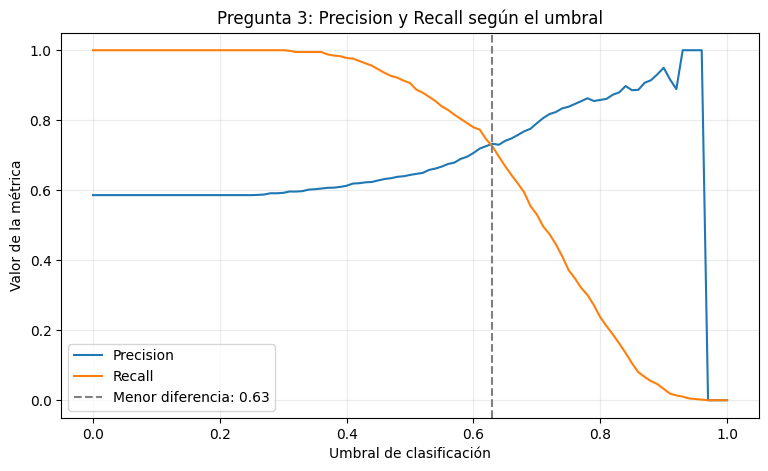

In [14]:
thresholds = np.linspace(0, 1, 101)
rows = []
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = ~predict_positive
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((round(float(t), 2), tp, fp, fn, tn, precision, recall))

df_scores = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall'])
valid_intersections = df_scores[(df_scores.precision != 0) | (df_scores.recall != 0)].copy()
valid_intersections['difference'] = abs(valid_intersections.precision - valid_intersections.recall)
closest = valid_intersections.sort_values(['difference', 'threshold']).iloc[0]
respuesta_q3 = float(closest.threshold)

display(valid_intersections.nsmallest(5, 'difference').round(4))
print(f'RESPUESTA Q3 — Umbral de intersección: {respuesta_q3:.2f}')

plt.figure(figsize=(9, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.axvline(respuesta_q3, linestyle='--', color='gray', label=f'Menor diferencia: {respuesta_q3:.2f}')
plt.xlabel('Umbral de clasificación')
plt.ylabel('Valor de la métrica')
plt.title('Pregunta 3: Precision y Recall según el umbral')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Pregunta 4 — F1 Score
F1 equilibra precision y recall: $F_1 = 2\cdot\frac{P\cdot R}{P+R}$. Para el denominador 0 usamos F1 = 0. Elegimos el **umbral que maximiza F1** sobre la misma grilla de 101 valores.

,threshold,precision,recall,f1
41,0.41,0.6190,0.9761,0.7576
42,0.42,0.6201,0.9693,0.7563
43,0.43,0.6225,0.9625,0.7560
45,0.45,0.6281,0.9454,0.7548
44,0.44,0.6236,0.9556,0.7547
46,0.46,0.6321,0.9352,0.7543
48,0.48,0.6383,0.9215,0.7542
40,0.40,0.6128,0.9778,0.7535
47,0.47,0.6343,0.9266,0.7531
50,0.50,0.6436,0.9061,0.7527


RESPUESTA Q4 — Umbral máximo F1: 0.41 (F1=0.7576)
Opciones de la tarea: 0.21 | 0.41 | 0.61 | 0.81


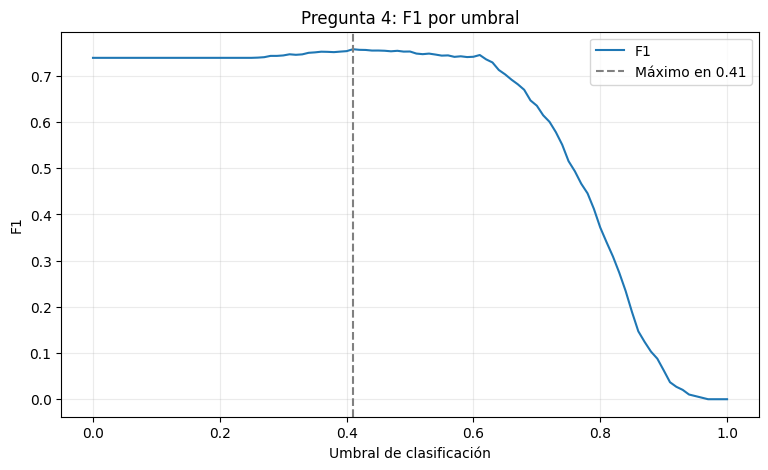

In [7]:
p = df_scores.precision
r = df_scores.recall
# Cuando p+r es 0, se asigna un F1 igual a 0.
df_scores['f1'] = np.where((p + r) > 0, 2 * p * r / (p + r).replace(0, np.nan), 0.0)
best_f1 = df_scores.sort_values(['f1', 'threshold'], ascending=[False, True]).iloc[0]
respuesta_q4 = float(best_f1.threshold)

display(df_scores.nlargest(10, 'f1')[['threshold', 'precision', 'recall', 'f1']].round(4))
print(f'RESPUESTA Q4 — Umbral máximo F1: {respuesta_q4:.2f} (F1={best_f1.f1:.4f})')

plt.figure(figsize=(9, 5))
plt.plot(df_scores.threshold, df_scores.f1, label='F1')
plt.axvline(respuesta_q4, linestyle='--', color='gray', label=f'Máximo en {respuesta_q4:.2f}')
plt.xlabel('Umbral de clasificación')
plt.ylabel('F1')
plt.title('Pregunta 4: F1 por umbral')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Funciones reutilizables para Q5 y Q6
Igual que en la sección de **Cross-Validation de Clase 4**, definimos `train()` y `predict()`.

**Importante:** `DictVectorizer` se ajusta de nuevo dentro de cada fold. Así evitamos aprender categorías de validación durante el entrenamiento de cada fold.

In [8]:
def train(df_part, y_part, C=1.0):
    records = df_part[categorical + numerical].to_dict(orient='records')
    vectorizer = DictVectorizer(sparse=False)
    X_part = vectorizer.fit_transform(records)
    classifier = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    classifier.fit(X_part, y_part)
    return vectorizer, classifier


def predict(df_part, vectorizer, classifier):
    records = df_part[categorical + numerical].to_dict(orient='records')
    X_part = vectorizer.transform(records)
    return classifier.predict_proba(X_part)[:, 1]


def cross_validate(full_train, C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    auc_scores = []
    for train_idx, val_idx in kfold.split(full_train):
        fold_train = full_train.iloc[train_idx]
        fold_val = full_train.iloc[val_idx]
        y_fold_train = fold_train[TARGET].values
        y_fold_val = fold_val[TARGET].values
        # La columna converted nunca entra en la codificación.
        dv_fold, model_fold = train(fold_train.drop(columns=[TARGET]), y_fold_train, C=C)
        pred_fold = predict(fold_val.drop(columns=[TARGET]), dv_fold, model_fold)
        auc_scores.append(roc_auc_score(y_fold_val, pred_fold))
    return np.array(auc_scores)

## Pregunta 5 — Validación cruzada de 5 folds
Medimos AUC en cada fold de `df_full_train` y calculamos su desviación estándar con `np.std()` (como en clase). No se usa el test.

In [15]:
scores_q5 = cross_validate(df_full_train, C=1.0)
respuesta_q5 = scores_q5.std()

print('AUC por fold:', np.round(scores_q5, 5))
print(f'Promedio: {scores_q5.mean():.3f}')
print(f'RESPUESTA Q5 — Desviación estándar: {respuesta_q5:.3f}')

AUC por fold: [0.73056 0.72957 0.73634 0.74125 0.72091]
Promedio: 0.732
RESPUESTA Q5 — Desviación estándar: 0.007


## Pregunta 6 — Ajuste del hiperparámetro C
Ejecutamos los 5 folds para **cada** valor de `C` solicitado: `0.000001`, `0.001` y `1`. El criterio de selección es: **mayor AUC promedio redondeado a 3 decimales; en empate, menor desviación estándar redondeada; si persiste empate, menor C**.

In [10]:
results_q6 = []
for C in [0.000001, 0.001, 1]:
    scores = cross_validate(df_full_train, C=C)
    results_q6.append({
        'C': C,
        'mean_auc': scores.mean(),
        'std_auc': scores.std(),
        'mean_3dec': round(float(scores.mean()), 3),
        'std_3dec': round(float(scores.std()), 3)
    })

q6_table = pd.DataFrame(results_q6)
display(q6_table)
chosen_q6 = q6_table.sort_values(
    ['mean_3dec', 'std_3dec', 'C'], ascending=[False, True, True]
).iloc[0]
respuesta_q6 = float(chosen_q6.C)
print(f'RESPUESTA Q6 — Mejor C: {respuesta_q6:g}')

,C,mean_auc,std_auc,mean_3dec,std_3dec
0,0.000001,0.616734,0.018670,0.617,0.019
1,0.001000,0.749172,0.009996,0.749,0.010
2,1.000000,0.731727,0.006853,0.732,0.007


RESPUESTA Q6 — Mejor C: 0.001
